In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models, transforms
from torchvision.models import ResNet18_Weights

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [ ]:
weights = ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 141MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
for param in model.parameters():
    param.requires_grad = False

print("Pretrained layers frozen!")

Pretrained layers frozen!


In [ ]:
number_of_features = model.fc.in_features

model.fc = nn.Linear(
    number_of_features,
    2
)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=2, bias=True)


In [ ]:
transform = weights.transforms()

print(transform)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [ ]:

import requests
import zipfile
from pathlib import Path

url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"

response = requests.get(url, timeout=120)
print("Status:", response.status_code)
print("File size:", len(response.content))

response.raise_for_status()

with open("cats_and_dogs.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("cats_and_dogs.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted!")

base_dir = Path("cats_and_dogs_filtered")
print("Dataset folder exists:", base_dir.exists())
print("Training folder exists:", (base_dir / "train").exists())


Status: 200
File size: 68606236
Dataset downloaded and extracted!
Dataset folder exists: True
Training folder exists: True


In [ ]:
from torchvision import datasets
from torch.utils.data import DataLoader

data_dir = Path("cats_and_dogs_filtered")

train_dataset = datasets.ImageFolder(
    data_dir / "train",
    transform=transform
)

val_dataset = datasets.ImageFolder(
    data_dir / "validation",
    transform=transform
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['cats', 'dogs']
Training images: 2000
Validation images: 1000


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

In [ ]:
epochs = 3

for epoch in range(epochs):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total
    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {average_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%}"
    )

Epoch 1/3 | Loss: 0.2781 | Train Accuracy: 89.50%
Epoch 2/3 | Loss: 0.1262 | Train Accuracy: 96.25%
Epoch 3/3 | Loss: 0.1086 | Train Accuracy: 95.95%


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

val_accuracy = correct / total

print(f"Validation Accuracy: {val_accuracy:.2%}")

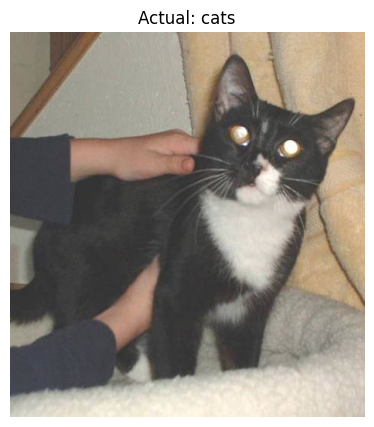

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path, actual_label = val_dataset.samples[0]

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(f"Actual: {val_dataset.classes[actual_label]}")
plt.axis("off")
plt.show()